In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataframe = pd.read_csv('cuerpos_nasa_sin_datosperdidos.csv', sep=',')
clasificadores = ['No Metálico', 'Metálico']

In [40]:
dataframe.head(10)

,Masa,Caida,Anio,Latitud,Longitud,Resultado
0,4.73,1,1880,35.33,51.63,1
1,2.55,0,2002,19.98,56.43,1
2,2.79,0,2001,29.27,11.54,0
3,1.59,0,2010,-25.23,-69.72,1
4,4.86,0,1856,37.75,-85.50,1
5,4.26,0,2002,20.01,56.42,1
6,0.26,0,2006,-72.78,75.31,0
7,3.64,0,1911,49.22,15.80,1
8,5.29,0,1889,38.82,-84.60,1
9,0.52,0,1986,-71.50,35.67,0


In [41]:
dataframe.groupby('Resultado').size()

Resultado
0    1113
1    1113
dtype: int64

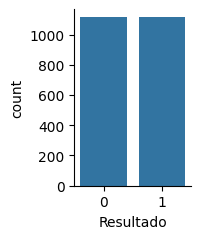

In [42]:
import seaborn as sb
sb.catplot(x='Resultado', data=dataframe, kind="count", height=2.5, aspect = .8)

In [43]:
Y = dataframe['Resultado']
X = dataframe.drop('Resultado', axis=1)

              precision    recall  f1-score   support

 No Metálico       0.82      0.82      0.82       333
    Metálico       0.82      0.82      0.82       335

    accuracy                           0.82       668
   macro avg       0.82      0.82      0.82       668
weighted avg       0.82      0.82      0.82       668


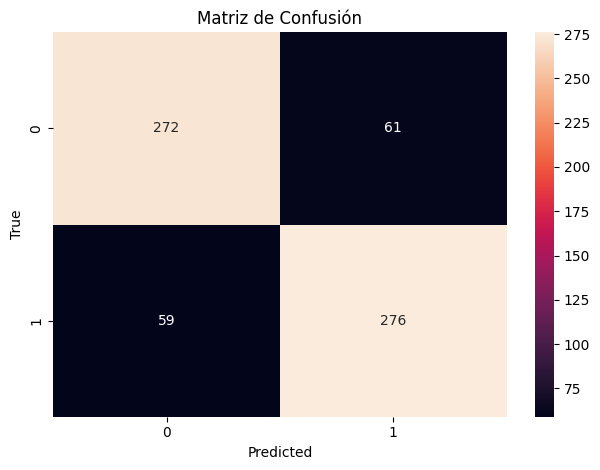

In [44]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=30)

from sklearn.neighbors import KNeighborsClassifier
knn_mm = KNeighborsClassifier(n_neighbors=1)
knn_mm.fit(X_train, Y_train)

predicciones = knn_mm.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix
sns.heatmap(confusion_matrix(Y_test, predicciones), annot=True, fmt='d')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
print(classification_report(Y_test, predicciones, target_names=clasificadores))

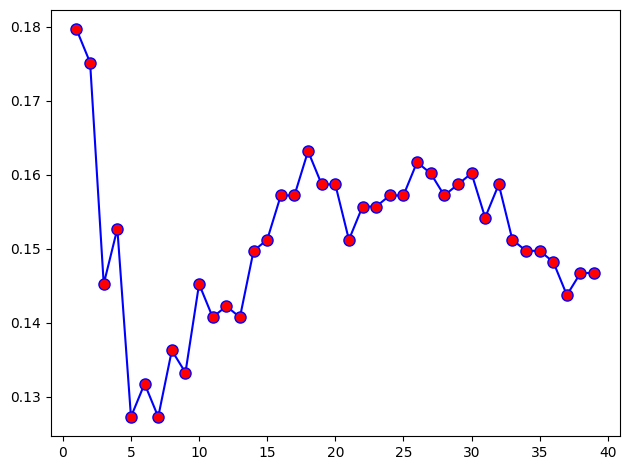

In [45]:
tasa_error = []
for i in range(1,40):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train, Y_train)
    predicciones_i = knn.predict(X_test)
    tasa_error.append(np.mean(predicciones_i != Y_test))

valores = range(1,40)
plt.plot(valores, tasa_error, color='blue', marker='o', markerfacecolor='red', markersize=8)

              precision    recall  f1-score   support

 No Metálico       0.86      0.89      0.88       333
    Metálico       0.89      0.85      0.87       335

    accuracy                           0.87       668
   macro avg       0.87      0.87      0.87       668
weighted avg       0.87      0.87      0.87       668


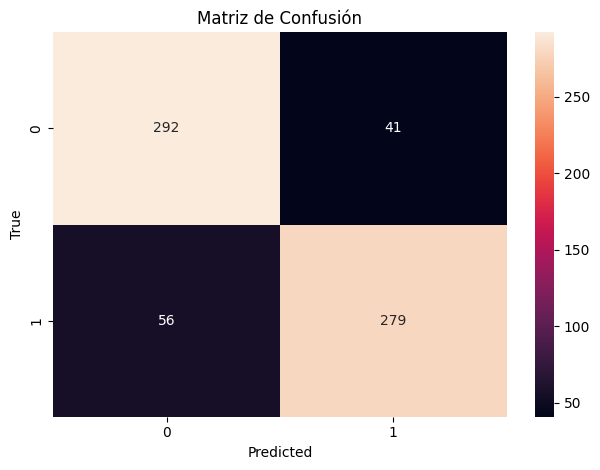

In [46]:
from sklearn.neighbors import KNeighborsClassifier
knn_mm = KNeighborsClassifier(n_neighbors=5)
knn_mm.fit(X_train, Y_train)

predicciones = knn_mm.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix
sns.heatmap(confusion_matrix(Y_test, predicciones), annot=True, fmt='d')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
print(classification_report(Y_test, predicciones, target_names=clasificadores))

In [47]:
print(knn_mm.predict([[4.8, 0, 1990, -25.0, -69.5]]))
print(knn_mm.predict_proba([[4.8, 0, 1990, -25.0, -69.5]]))

[1]
[[0. 1.]]


In [48]:
import joblib
joblib.dump(knn_mm, "knn_cuerpos_nasa.joblib")